# Data exploration

Eight NBA regular seasons (2018-19 to 2025-26) of player season totals, scored with this project's fantasy rules. This notebook will look at how fantasy value is distributed, how it differs by position, how predictable it is from one season to the next, and how it changes with age.

In [4]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # make the project root importable

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import config
from src.scoring import (
    load_player_seasons, add_missed_shots, add_fantasy_points,
    add_per_game, load_players, add_positions,
)

sns.set_theme(style="whitegrid")

In [ ]:
df = load_player_seasons()
df = add_missed_shots(df)
df = add_fantasy_points(df)
df = add_per_game(df)
df = add_positions(df, load_players())

qualified = df[df["MIN"] >= config.MIN_MINUTES]
print(f"All player seasons: {len(df)}")
print(f"With {config.MIN_MINUTES}+ minutes: {len(qualified)}")
qualified[["FANTASY_PTS", "FANTASY_PPG", "GP", "MIN", "AGE"]].describe().round(1)

2,917 player seasons have 500+ minutes, about 365 per season. The league drafts 144 players, so roughly the top 40% of qualified players. The mean (1,845) is above the median (1,627) which means value is concentrated in a small group of stars. The extreme values check out: the 43-year-old is Vince Carter (2019-20), and 84 games comes from a midseason trade where the player's new team had played fewer games in that season than his old team.

## How fast does fantasy value drop off?

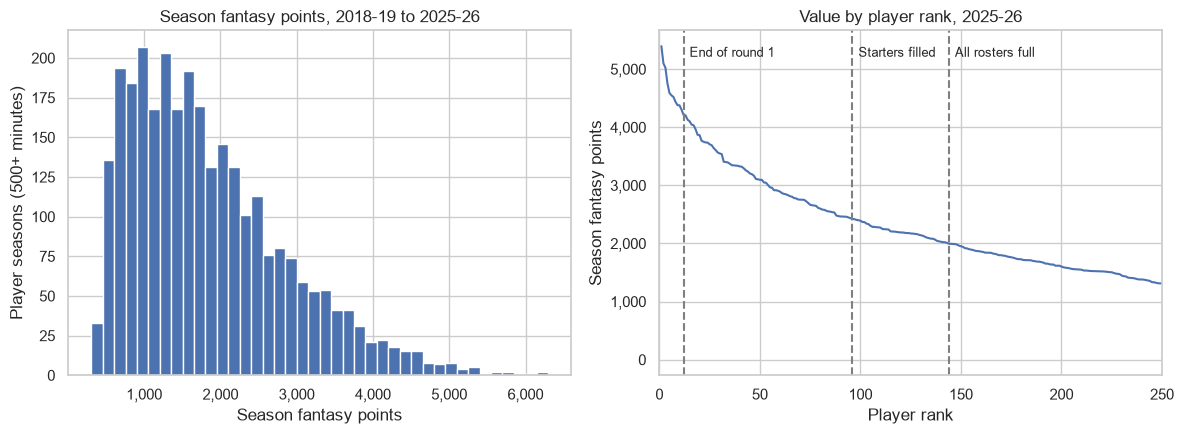

Rank 1: 5,396 points
Rank 12: 4,214 points
Rank 48: 3,110 points
Rank 96: 2,424 points
Rank 144: 1,995 points


In [18]:
from matplotlib.ticker import StrMethodFormatter

season = df[df["SEASON"] == config.TEST_SEASON].sort_values("FANTASY_PTS", ascending=False)
season_ranks = range(1, len(season) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.hist(qualified["FANTASY_PTS"], bins=40)
ax1.set_title("Season fantasy points, 2018-19 to 2025-26")
ax1.set_xlabel("Season fantasy points")
ax1.set_ylabel("Player seasons (500+ minutes)")
ax1.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax2.plot(season_ranks, season["FANTASY_PTS"])
ax2.set_xlim(0, 250)
for rank, label in [(12, "End of round 1"), (96, "Starters filled"), (144, "All rosters full")]:
    ax2.axvline(rank, color="gray", linestyle="--")
    ax2.text(rank + 3, ax2.get_ylim()[1] * 0.92, label, fontsize=9)
ax2.set_title(f"Value by player rank, {config.TEST_SEASON}")
ax2.set_xlabel("Player rank")
ax2.set_ylabel("Season fantasy points")
ax2.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

fig.tight_layout()
fig.savefig(config.PROJECT_ROOT / "outputs" / "value_dropoff.png", dpi=150, bbox_inches="tight")
plt.show()

for rank in [1, 12, 48, 96, 144]:
    print(f"Rank {rank}: {season['FANTASY_PTS'].iloc[rank - 1]:,.0f} points")